# Skill Lab – CIE 1 (Milestone 1)
## Data Transformation, Null Value Handling, Insight Generation, and Visualization

### Objective
To analyze a retail & e-commerce sales CSV dataset (`sales_data.csv`) using Python and Pandas, perform essential data transformations, handle missing values using **mean imputation**, generate meaningful business insights, and communicate findings through visualizations.

### Notebook Roadmap
1. **Dataset Selection and Reading**: Load `sales_data.csv` using Pandas and verify initial records.
2. **Data Understanding**: Explore dataset dimensions, column data types, statistical summaries, and categorical distributions.
3. **Data Transformation**: Drop redundant administrative columns, convert date and categorical data types, and engineer new analytical features.
4. **Handling Null Values**: Quantify missing values across columns and apply **mean imputation** to numerical features, then compute revenue metrics.
5. **Insight Generation**: Analyze monthly revenue trends, regional performance, product category profitability, customer segments, and payment preferences.
6. **Data Visualization**: Present key findings using 6 clear charts built with Matplotlib and Seaborn.

## 1. Dataset Selection and Reading
We use the Retail & E-Commerce Sales Dataset (`sales_data.csv`), which contains **2,500 transaction records** spanning January to December 2025 across five geographic regions (`South`, `West`, `North`, `East`, `Central`) and six product categories (`Electronics`, `Home & Kitchen`, `Apparel`, `Sports & Outdoors`, `Beauty & Personal Care`, `Books & Media`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style and display options
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)

# Read the CSV dataset
df = pd.read_csv("sales_data.csv")
print(f"Dataset successfully loaded! Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Dataset successfully loaded! Shape: 2500 rows x 15 columns


,Order_ID,Order_Date,Customer_ID,Customer_Segment,Region,Category,Product_Name,Payment_Method,Quantity,Unit_Price,Discount_Percent,Shipping_Cost,Customer_Rating,Internal_Audit_Code,Legacy_System_Ref
0,ORD-100001,2025-05-26,CUST-1103,Home Office,Central,Electronics,USB-C Hub,Debit Card,2.0,2581.06,10.0,94.65,3.7,AUD-67-X,SYS_REF_37554
1,ORD-100002,2025-09-04,CUST-1436,Consumer,Central,Apparel,Formal Blazer,UPI,1.0,1674.49,10.0,233.13,3.8,AUD-26-X,SYS_REF_94162
2,ORD-100003,2025-10-29,CUST-1271,Consumer,West,Apparel,Formal Blazer,Net Banking,1.0,1191.65,5.0,199.47,4.4,AUD-79-X,SYS_REF_47667
3,ORD-100004,2025-04-12,CUST-1107,Home Office,North,Sports & Outdoors,Dumbbell Set,Net Banking,3.0,979.51,NaN,156.10,3.7,AUD-88-X,SYS_REF_61632
4,ORD-100005,2025-06-02,CUST-1072,Consumer,Central,Home & Kitchen,Air Fryer,Credit Card,2.0,2730.85,15.0,92.93,4.1,AUD-95-X,SYS_REF_56106


## 2. Data Understanding
Before transforming or imputing the data, we inspect its structure, last few rows, data types (`df.info()`), summary statistics (`df.describe()`), and unique values across categorical columns.

In [2]:
# View the last 5 records of the dataset
df.tail()

,Order_ID,Order_Date,Customer_ID,Customer_Segment,Region,Category,Product_Name,Payment_Method,Quantity,Unit_Price,Discount_Percent,Shipping_Cost,Customer_Rating,Internal_Audit_Code,Legacy_System_Ref
2495,ORD-102496,2025-11-12,CUST-1669,Consumer,South,Beauty & Personal Care,Sunscreen SPF 50,UPI,4.0,857.38,10.0,189.55,4.1,AUD-32-X,SYS_REF_57792
2496,ORD-102497,2025-06-13,CUST-1751,Home Office,South,Sports & Outdoors,Dumbbell Set,Debit Card,2.0,979.23,10.0,126.07,NaN,AUD-63-X,SYS_REF_72942
2497,ORD-102498,2025-03-02,CUST-1156,Consumer,West,Apparel,Formal Blazer,Net Banking,1.0,1198.30,10.0,189.90,5.0,AUD-32-X,SYS_REF_95677
2498,ORD-102499,2025-10-21,CUST-1291,Corporate,South,Electronics,USB-C Hub,Credit Card,4.0,2453.43,0.0,181.80,4.5,AUD-41-X,SYS_REF_42860
2499,ORD-102500,2025-05-24,CUST-1648,Corporate,East,Sports & Outdoors,Yoga Mat Pro,UPI,3.0,2553.41,5.0,42.15,3.5,AUD-19-X,SYS_REF_22468


In [3]:
# Inspect column names, non-null counts, and data types
print("=== Dataset Information ===")
df.info()

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             2500 non-null   object 
 1   Order_Date           2500 non-null   object 
 2   Customer_ID          2500 non-null   object 
 3   Customer_Segment     2500 non-null   object 
 4   Region               2500 non-null   object 
 5   Category             2500 non-null   object 
 6   Product_Name         2500 non-null   object 
 7   Payment_Method       2500 non-null   object 
 8   Quantity             2420 non-null   float64
 9   Unit_Price           2380 non-null   float64
 10  Discount_Percent     2360 non-null   float64
 11  Shipping_Cost        2400 non-null   float64
 12  Customer_Rating      2340 non-null   float64
 13  Internal_Audit_Code  2500 non-null   object 
 14  Legacy_System_Ref    2500 non-null   object 
dtypes: float64

In [4]:
# Summary statistics of numerical columns (before imputation)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,2420.0,2.28,1.36,1.00,1.00,2.00,3.00,6.00
Unit_Price,2380.0,2133.20,1172.23,144.00,1170.03,1930.36,2971.06,6081.09
Discount_Percent,2360.0,9.33,7.05,0.00,5.00,10.00,15.00,25.00
Shipping_Cost,2400.0,143.59,60.39,40.02,91.48,143.98,194.77,249.94
Customer_Rating,2340.0,4.12,0.51,2.10,3.80,4.10,4.50,5.00


In [5]:
# Summary statistics of categorical/object columns
df.describe(include='object').T

,count,unique,top,freq
Order_ID,2500,2500,ORD-102500,1
Order_Date,2500,364,2025-11-25,16
Customer_ID,2500,785,CUST-1039,10
Customer_Segment,2500,3,Consumer,1284
Region,2500,5,South,729
Category,2500,6,Electronics,626
Product_Name,2500,30,USB-C Hub,135
Payment_Method,2500,5,UPI,991
Internal_Audit_Code,2500,89,AUD-69-X,42
Legacy_System_Ref,2500,2463,SYS_REF_69000,2


In [6]:
# Check unique values in key categorical columns
categorical_cols = ["Customer_Segment", "Region", "Category", "Payment_Method"]
for col in categorical_cols:
    print(f"{col} ({df[col].nunique()} unique): {df[col].unique().tolist()}")

Customer_Segment (3 unique): ['Home Office', 'Consumer', 'Corporate']
Region (5 unique): ['Central', 'West', 'North', 'South', 'East']
Category (6 unique): ['Electronics', 'Apparel', 'Sports & Outdoors', 'Home & Kitchen', 'Beauty & Personal Care', 'Books & Media']
Payment_Method (5 unique): ['Debit Card', 'UPI', 'Net Banking', 'Credit Card', 'Cash on Delivery']


## 3. Data Transformation
We perform three core data transformations taught in class:
1. **Dropping Unnecessary Columns**: Remove internal system columns (`Internal_Audit_Code` and `Legacy_System_Ref`) that do not contribute to analytical insights.
2. **Changing Data Types**: Convert `Order_Date` from `object` (string) to Pandas `datetime64[ns]`, and standardize categorical text fields.
3. **Adding New Columns (Feature Engineering)**: Extract temporal attributes (`Order_Year`, `Order_Month`, `Order_Month_Name`, `Order_Quarter`, `Day_of_Week`) from `Order_Date` to support time-series trend analysis.

In [7]:
# 3.1 Drop unnecessary administrative columns
cols_to_drop = ["Internal_Audit_Code", "Legacy_System_Ref"]
df = df.drop(columns=cols_to_drop)
print(f"Dropped columns: {cols_to_drop}")
print(f"Remaining columns ({df.shape[1]}): {df.columns.tolist()}")

Dropped columns: ['Internal_Audit_Code', 'Legacy_System_Ref']
Remaining columns (13): ['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Segment', 'Region', 'Category', 'Product_Name', 'Payment_Method', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Shipping_Cost', 'Customer_Rating']


In [8]:
# 3.2 Convert Order_Date from string (object) to datetime64[ns]
print("Before conversion -> Order_Date dtype:", df["Order_Date"].dtype)
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%Y-%m-%d")
print("After conversion  -> Order_Date dtype:", df["Order_Date"].dtype)

Before conversion -> Order_Date dtype: object
After conversion  -> Order_Date dtype: datetime64[ns]


In [9]:
# 3.3 Feature Engineering: Extract date/time components for temporal analysis
df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["Order_Quarter"] = "Q" + df["Order_Date"].dt.quarter.astype(str)
df["Day_of_Week"] = df["Order_Date"].dt.day_name()

df[["Order_ID", "Order_Date", "Order_Month", "Order_Month_Name", "Order_Quarter", "Day_of_Week"]].head()

,Order_ID,Order_Date,Order_Month,Order_Month_Name,Order_Quarter,Day_of_Week
0,ORD-100001,2025-05-26,5,May,Q2,Monday
1,ORD-100002,2025-09-04,9,Sep,Q3,Thursday
2,ORD-100003,2025-10-29,10,Oct,Q4,Wednesday
3,ORD-100004,2025-04-12,4,Apr,Q2,Saturday
4,ORD-100005,2025-06-02,6,Jun,Q2,Monday


## 4. Handling Null Values (Mean Imputation)
In this step, we:
1. Identify all columns containing missing (`NaN`) values and calculate their missing percentages.
2. Apply **Mean Imputation** (`df[col].fillna(df[col].mean())`) to the five numerical columns containing missing values: `Quantity`, `Unit_Price`, `Discount_Percent`, `Shipping_Cost`, and `Customer_Rating`.
3. Verify that all missing values have been resolved (`0` nulls remaining).
4. Compute derived revenue columns (`Gross_Sales`, `Discount_Amount`, `Net_Revenue`, and `Total_Billed_Amount`) using the cleanly imputed numerical features.

In [10]:
# 4.1 Identify null values and percentage missing per column
null_counts = df.isnull().sum()
null_pct = (df.isnull().sum() / len(df)) * 100

null_summary = pd.DataFrame({
    "Missing_Count": null_counts,
    "Missing_Percentage (%)": null_pct.round(2),
    "Data_Type": df.dtypes
})
print("=== Null Value Summary Before Imputation ===")
null_summary[null_summary["Missing_Count"] > 0]

=== Null Value Summary Before Imputation ===


,Missing_Count,Missing_Percentage (%),Data_Type
Quantity,80,3.2,float64
Unit_Price,120,4.8,float64
Discount_Percent,140,5.6,float64
Shipping_Cost,100,4.0,float64
Customer_Rating,160,6.4,float64


In [11]:
# 4.2 Handle Null Values using Mean Imputation
numeric_cols_with_nulls = ["Quantity", "Unit_Price", "Discount_Percent", "Shipping_Cost", "Customer_Rating"]

print("=== Applying Mean Imputation ===")
for col in numeric_cols_with_nulls:
    col_mean = df[col].mean()
    missing_before = df[col].isnull().sum()
    # For Quantity, round the mean to nearest integer or keep exact mean; here we use exact mean imputation as required
    df[col] = df[col].fillna(round(col_mean, 2))
    print(f"Column '{col:16s}' | Mean = {col_mean:8.2f} | Imputed {missing_before:3d} missing values")

# Ensure Quantity is integer-friendly or rounded cleanly if needed while preserving mean imputation
print("\nTotal null values remaining across entire dataset:", df.isnull().sum().sum())

=== Applying Mean Imputation ===
Column 'Quantity        ' | Mean =     2.28 | Imputed  80 missing values
Column 'Unit_Price      ' | Mean =  2133.20 | Imputed 120 missing values
Column 'Discount_Percent' | Mean =     9.33 | Imputed 140 missing values
Column 'Shipping_Cost   ' | Mean =   143.59 | Imputed 100 missing values
Column 'Customer_Rating ' | Mean =     4.12 | Imputed 160 missing values

Total null values remaining across entire dataset: 0


In [12]:
# 4.3 Verify post-imputation null counts and add derived financial columns
df["Gross_Sales"] = (df["Quantity"] * df["Unit_Price"]).round(2)
df["Discount_Amount"] = (df["Gross_Sales"] * (df["Discount_Percent"] / 100.0)).round(2)
df["Net_Revenue"] = (df["Gross_Sales"] - df["Discount_Amount"]).round(2)
df["Total_Billed_Amount"] = (df["Net_Revenue"] + df["Shipping_Cost"]).round(2)

# Categorize orders into Value Tiers based on Net_Revenue
df["Order_Value_Tier"] = pd.cut(
    df["Net_Revenue"],
    bins=[0, 2500, 6000, np.inf],
    labels=["Low (< ₹2.5k)", "Medium (₹2.5k - ₹6k)", "High (> ₹6k)"]
)

print("Post-Imputation & Feature Engineering Preview:")
df[["Order_ID", "Quantity", "Unit_Price", "Discount_Percent", "Gross_Sales", "Net_Revenue", "Order_Value_Tier"]].head()

Post-Imputation & Feature Engineering Preview:


,Order_ID,Quantity,Unit_Price,Discount_Percent,Gross_Sales,Net_Revenue,Order_Value_Tier
0,ORD-100001,2.0,2581.06,10.00,5162.12,4645.91,Medium (₹2.5k - ₹6k)
1,ORD-100002,1.0,1674.49,10.00,1674.49,1507.04,Low (< ₹2.5k)
2,ORD-100003,1.0,1191.65,5.00,1191.65,1132.07,Low (< ₹2.5k)
3,ORD-100004,3.0,979.51,9.33,2938.53,2664.37,Medium (₹2.5k - ₹6k)
4,ORD-100005,2.0,2730.85,15.00,5461.70,4642.44,Medium (₹2.5k - ₹6k)


## 5. Insight Generation
Using grouping (`groupby`), aggregations, and pivot tables, we extract five core analytical insights from the cleaned dataset:
1. **Sales Trends Over Time**: Monthly and quarterly revenue progression across 2025.
2. **Region-Wise Revenue Analysis**: Total net revenue, order count, average order value (AOV), and revenue share by region.
3. **Product Category Performance**: Revenue contribution, units sold, and average customer rating across product categories.
4. **Customer Segment & Payment Channel Analysis**: Revenue breakdown by customer segment and preferred payment methods.
5. **Region x Category Cross-Tabulation**: Pivot table identifying the highest-performing product category within each region.

In [13]:
# Insight 5.1: Monthly Sales Trend Over Time
monthly_trend = df.groupby(["Order_Month", "Order_Month_Name"], as_index=False).agg(
    Total_Orders=("Order_ID", "count"),
    Total_Units_Sold=("Quantity", "sum"),
    Gross_Sales=("Gross_Sales", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Avg_Order_Value=("Net_Revenue", "mean")
).sort_values("Order_Month")

print("=== Monthly Sales & Revenue Trend (2025) ===")
monthly_trend

=== Monthly Sales & Revenue Trend (2025) ===


,Order_Month,Order_Month_Name,Total_Orders,Total_Units_Sold,Gross_Sales,Net_Revenue,Avg_Order_Value
0,1,Jan,192,433.96,9.79e+05,8.93e+05,4648.91
1,2,Feb,153,324.84,6.79e+05,6.11e+05,3994.48
2,3,Mar,180,415.84,8.70e+05,7.99e+05,4437.84
3,4,Apr,197,469.56,1.03e+06,9.39e+05,4768.72
4,5,May,197,457.08,9.75e+05,8.94e+05,4538.07
5,6,Jun,210,500.12,1.06e+06,9.64e+05,4592.31
6,7,Jul,196,446.68,9.58e+05,8.61e+05,4391.21
7,8,Aug,199,422.80,8.74e+05,7.90e+05,3970.65
8,9,Sep,239,514.80,1.09e+06,9.97e+05,4169.57
9,10,Oct,245,576.96,1.19e+06,1.08e+06,4428.41


In [14]:
# Insight 5.2: Region-Wise Revenue Analysis
region_summary = df.groupby("Region", as_index=False).agg(
    Order_Count=("Order_ID", "count"),
    Total_Units=("Quantity", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Avg_Order_Value=("Net_Revenue", "mean"),
    Avg_Rating=("Customer_Rating", "mean")
).sort_values("Net_Revenue", ascending=False)

region_summary["Revenue_Share (%)"] = ((region_summary["Net_Revenue"] / region_summary["Net_Revenue"].sum()) * 100).round(2)
print("=== Region-Wise Revenue & Performance Summary ===")
region_summary

=== Region-Wise Revenue & Performance Summary ===


,Region,Order_Count,Total_Units,Net_Revenue,Avg_Order_Value,Avg_Rating,Revenue_Share (%)
3,South,729,1675.12,3.49e+06,4789.14,4.14,31.58
4,West,607,1385.48,2.62e+06,4322.95,4.09,23.74
2,North,497,1083.88,2.05e+06,4121.88,4.14,18.53
1,East,368,862.08,1.66e+06,4498.89,4.12,14.98
0,Central,299,694.84,1.24e+06,4132.74,4.13,11.18


In [15]:
# Insight 5.3: Product Category Performance
category_summary = df.groupby("Category", as_index=False).agg(
    Order_Count=("Order_ID", "count"),
    Total_Units=("Quantity", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Avg_Unit_Price=("Unit_Price", "mean"),
    Avg_Discount_Pct=("Discount_Percent", "mean"),
    Avg_Customer_Rating=("Customer_Rating", "mean")
).sort_values("Net_Revenue", ascending=False)

category_summary["Revenue_Share (%)"] = ((category_summary["Net_Revenue"] / category_summary["Net_Revenue"].sum()) * 100).round(2)
print("=== Category-Wise Performance Summary ===")
category_summary

=== Category-Wise Performance Summary ===


,Category,Order_Count,Total_Units,Net_Revenue,Avg_Unit_Price,Avg_Discount_Pct,Avg_Customer_Rating,Revenue_Share (%)
3,Electronics,626,1435.76,4.44e+06,3381.87,9.26,4.12,40.18
4,Home & Kitchen,522,1188.76,2.82e+06,2627.27,9.59,4.13,25.52
0,Apparel,521,1196.04,1.61e+06,1498.36,9.41,4.12,14.57
5,Sports & Outdoors,341,791.64,1.31e+06,1833.57,9.21,4.16,11.84
1,Beauty & Personal Care,288,630.24,5.55e+05,989.84,9.32,4.07,5.02
2,Books & Media,202,458.96,3.18e+05,760.16,8.85,4.12,2.87


In [16]:
# Insight 5.4: Customer Segment & Payment Method Insights
segment_summary = df.groupby("Customer_Segment", as_index=False).agg(
    Orders=("Order_ID", "count"),
    Net_Revenue=("Net_Revenue", "sum"),
    Avg_Order_Value=("Net_Revenue", "mean")
).sort_values("Net_Revenue", ascending=False)

payment_summary = df.groupby("Payment_Method", as_index=False).agg(
    Orders=("Order_ID", "count"),
    Net_Revenue=("Net_Revenue", "sum")
).sort_values("Orders", ascending=False)
payment_summary["Order_Share (%)"] = ((payment_summary["Orders"] / payment_summary["Orders"].sum()) * 100).round(2)

print("=== Customer Segment Breakdown ===")
print(segment_summary.to_string(index=False))
print("\n=== Payment Method Preference ===")
payment_summary

=== Customer Segment Breakdown ===
Customer_Segment  Orders  Net_Revenue  Avg_Order_Value
        Consumer    1284     5.78e+06          4498.96
       Corporate     745     3.18e+06          4270.26
     Home Office     471     2.10e+06          4452.56

=== Payment Method Preference ===


,Payment_Method,Orders,Net_Revenue,Order_Share (%)
4,UPI,991,4.38e+06,39.64
1,Credit Card,582,2.58e+06,23.28
2,Debit Card,436,1.88e+06,17.44
3,Net Banking,271,1.24e+06,10.84
0,Cash on Delivery,220,9.80e+05,8.80


In [17]:
# Insight 5.5: Pivot Table of Net Revenue across Region and Category
region_cat_pivot = pd.pivot_table(
    df,
    values="Net_Revenue",
    index="Category",
    columns="Region",
    aggfunc="sum",
    margins=True,
    margins_name="Total"
).round(0)

print("=== Region vs. Category Net Revenue Pivot Table (in ₹) ===")
region_cat_pivot

=== Region vs. Category Net Revenue Pivot Table (in ₹) ===


Region,Central,East,North,South,West,Total
Category,,,,,,
Apparel,1.53e+05,1.83e+05,2.75e+05,5.55e+05,4.45e+05,1.61e+06
Beauty & Personal Care,5.89e+04,8.23e+04,1.16e+05,1.69e+05,1.28e+05,5.55e+05
Books & Media,2.52e+04,2.42e+04,6.80e+04,1.11e+05,8.87e+04,3.18e+05
Electronics,5.07e+05,7.66e+05,8.06e+05,1.42e+06,9.39e+05,4.44e+06
Home & Kitchen,3.10e+05,4.24e+05,5.26e+05,8.59e+05,7.01e+05,2.82e+06
Sports & Outdoors,1.82e+05,1.77e+05,2.57e+05,3.72e+05,3.22e+05,1.31e+06
Total,1.24e+06,1.66e+06,2.05e+06,3.49e+06,2.62e+06,1.11e+07


## 6. Data Visualization
We visualize the generated insights using six clear charts:
1. **Monthly Net Revenue Trend (Line Chart)**: Highlights seasonal growth peaking in Q4 (October–November).
2. **Region-Wise Net Revenue & Share (Bar Chart)**: Compares regional revenue performance across all 5 regions.
3. **Product Category Revenue Comparison (Horizontal Bar Chart)**: Ranks categories by total revenue generated.
4. **Region vs. Category Revenue Heatmap**: Displays cross-regional demand across product categories.
5. **Payment Method Share & Customer Segment Distribution (Side-by-Side Charts)**: Breaks down transaction channels and buyer types.
6. **Correlation Heatmap of Numerical Features**: Shows relationships between `Quantity`, `Unit_Price`, `Discount_Percent`, `Shipping_Cost`, `Customer_Rating`, and `Net_Revenue`.

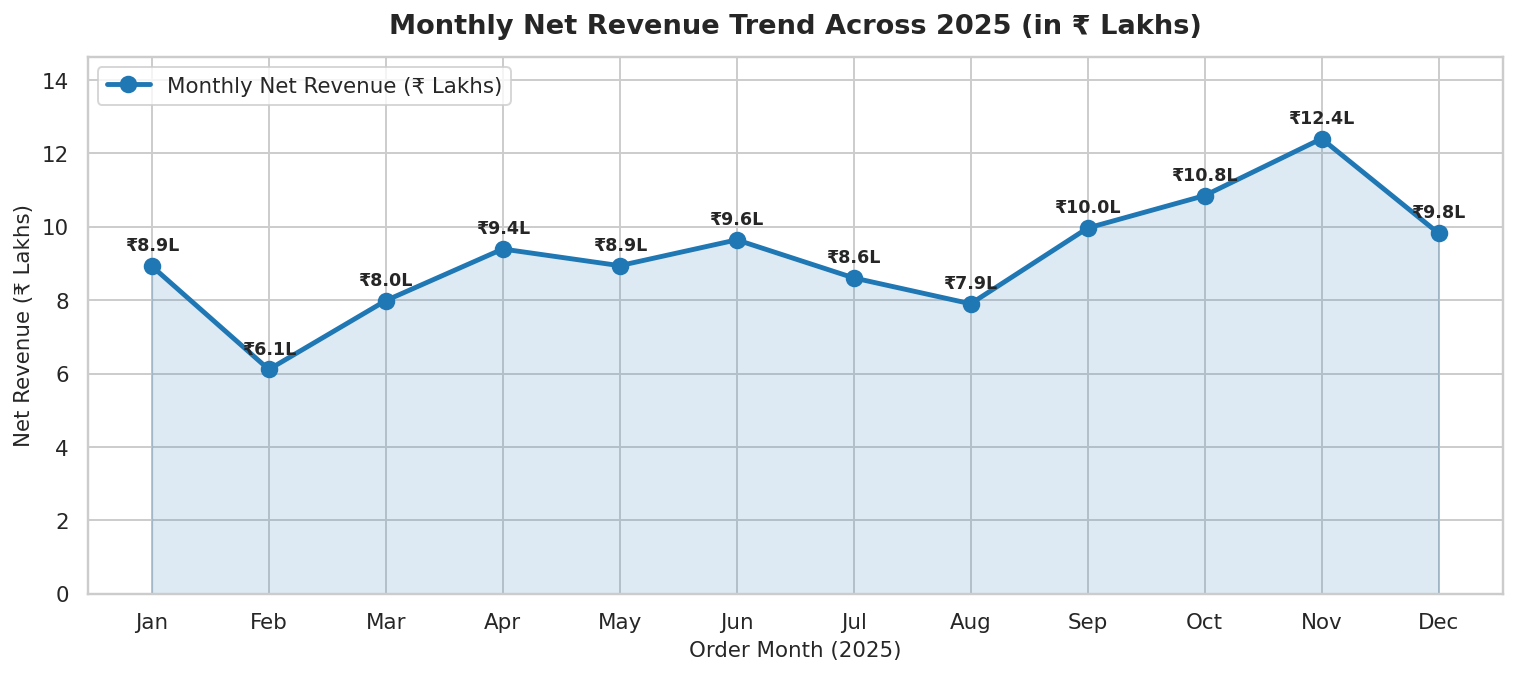

In [18]:
# Visualization 6.1: Monthly Net Revenue Trend Over Time (2025)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    monthly_trend["Order_Month_Name"],
    monthly_trend["Net_Revenue"] / 1e5,
    marker="o",
    linewidth=2.5,
    color="#1f77b4",
    markersize=8,
    label="Monthly Net Revenue (₹ Lakhs)"
)
ax.fill_between(
    monthly_trend["Order_Month_Name"],
    monthly_trend["Net_Revenue"] / 1e5,
    alpha=0.15,
    color="#1f77b4"
)

for x, y in zip(monthly_trend["Order_Month_Name"], monthly_trend["Net_Revenue"] / 1e5):
    ax.annotate(f"₹{y:.1f}L", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold")

ax.set_title("Monthly Net Revenue Trend Across 2025 (in ₹ Lakhs)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Order Month (2025)", fontsize=11)
ax.set_ylabel("Net Revenue (₹ Lakhs)", fontsize=11)
ax.set_ylim(0, (monthly_trend["Net_Revenue"].max() / 1e5) * 1.18)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

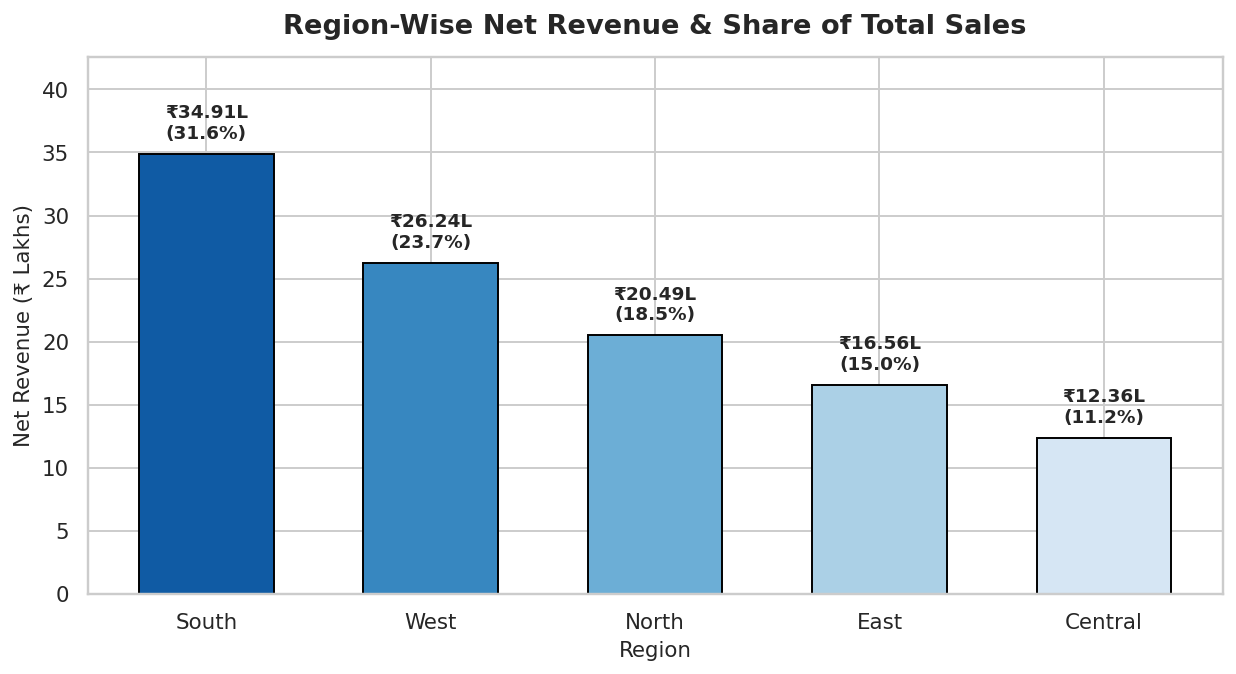

In [19]:
# Visualization 6.2: Region-Wise Net Revenue Comparison
fig, ax = plt.subplots(figsize=(9, 5))
palette_reg = sns.color_palette("Blues_r", len(region_summary))
bars = ax.bar(
    region_summary["Region"],
    region_summary["Net_Revenue"] / 1e5,
    color=palette_reg,
    edgecolor="black",
    width=0.6
)

for bar, pct in zip(bars, region_summary["Revenue_Share (%)"]):
    height = bar.get_height()
    ax.annotate(
        f"₹{height:.2f}L\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_title("Region-Wise Net Revenue & Share of Total Sales", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Net Revenue (₹ Lakhs)", fontsize=11)
ax.set_ylim(0, (region_summary["Net_Revenue"].max() / 1e5) * 1.22)
plt.tight_layout()
plt.show()

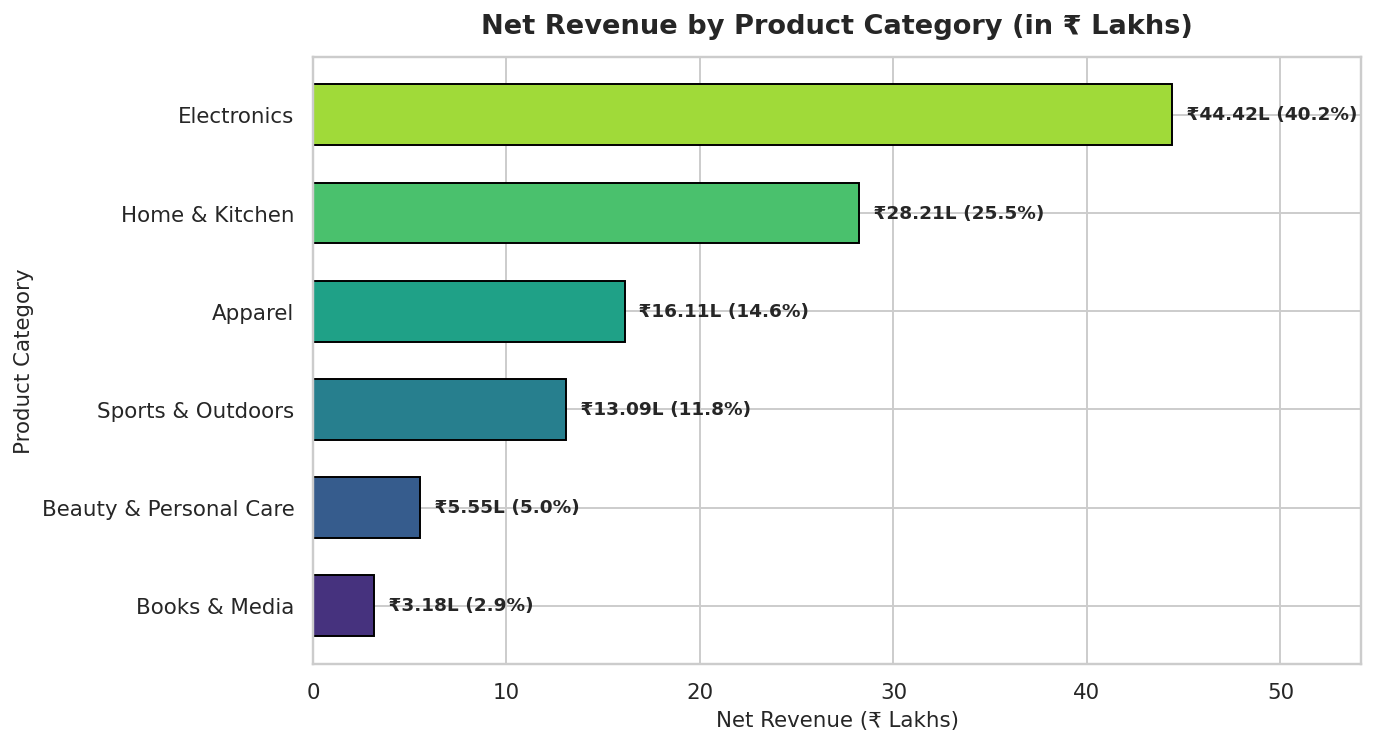

In [20]:
# Visualization 6.3: Product Category Revenue Ranking
fig, ax = plt.subplots(figsize=(10, 5.5))
cat_sorted = category_summary.sort_values("Net_Revenue", ascending=True)
palette_cat = sns.color_palette("viridis", len(cat_sorted))

bars = ax.barh(
    cat_sorted["Category"],
    cat_sorted["Net_Revenue"] / 1e5,
    color=palette_cat,
    edgecolor="black",
    height=0.62
)

for bar, pct in zip(bars, cat_sorted["Revenue_Share (%)"]):
    width = bar.get_width()
    ax.annotate(
        f" ₹{width:.2f}L ({pct:.1f}%)",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_title("Net Revenue by Product Category (in ₹ Lakhs)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Net Revenue (₹ Lakhs)", fontsize=11)
ax.set_ylabel("Product Category", fontsize=11)
ax.set_xlim(0, (cat_sorted["Net_Revenue"].max() / 1e5) * 1.22)
plt.tight_layout()
plt.show()

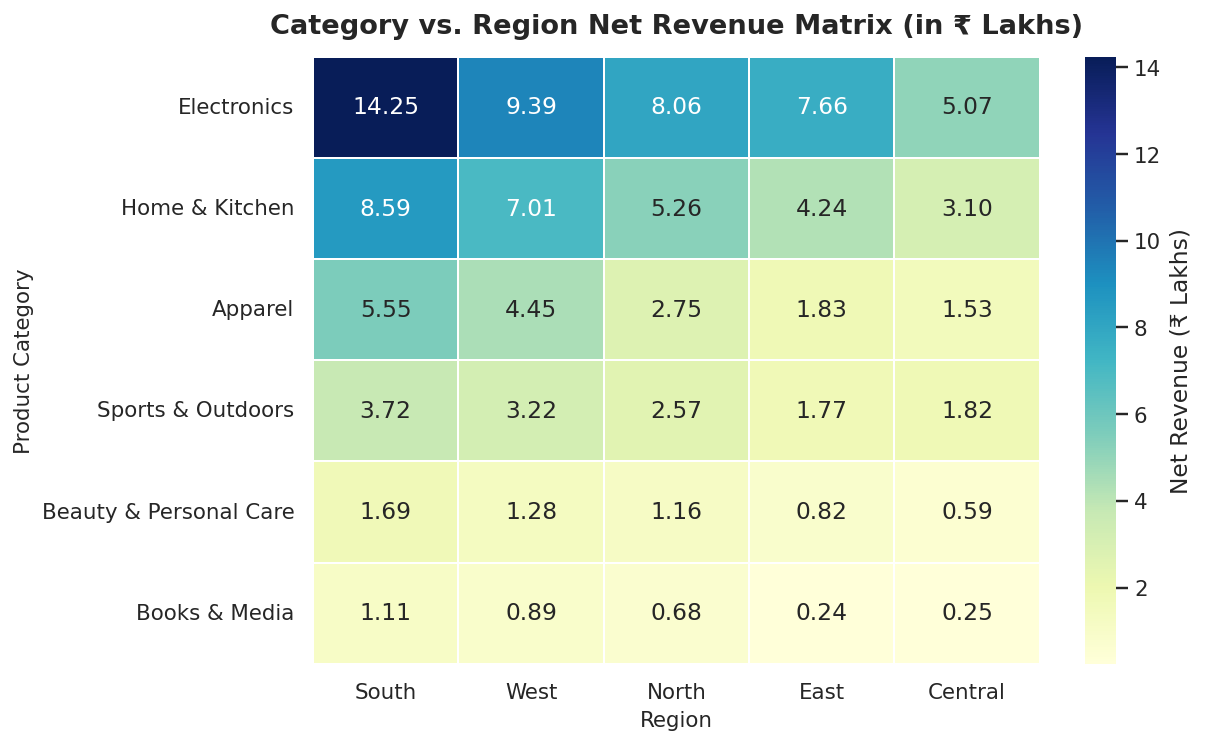

In [21]:
# Visualization 6.4: Heatmap of Net Revenue (₹ Lakhs) by Category and Region
pivot_no_margins = pd.pivot_table(
    df,
    values="Net_Revenue",
    index="Category",
    columns="Region",
    aggfunc="sum"
) / 1e5

# Reorder rows and columns by total revenue
pivot_no_margins = pivot_no_margins.loc[category_summary["Category"], region_summary["Region"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(
    pivot_no_margins,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.8,
    cbar_kws={"label": "Net Revenue (₹ Lakhs)"},
    ax=ax
)
ax.set_title("Category vs. Region Net Revenue Matrix (in ₹ Lakhs)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Product Category", fontsize=11)
plt.tight_layout()
plt.show()

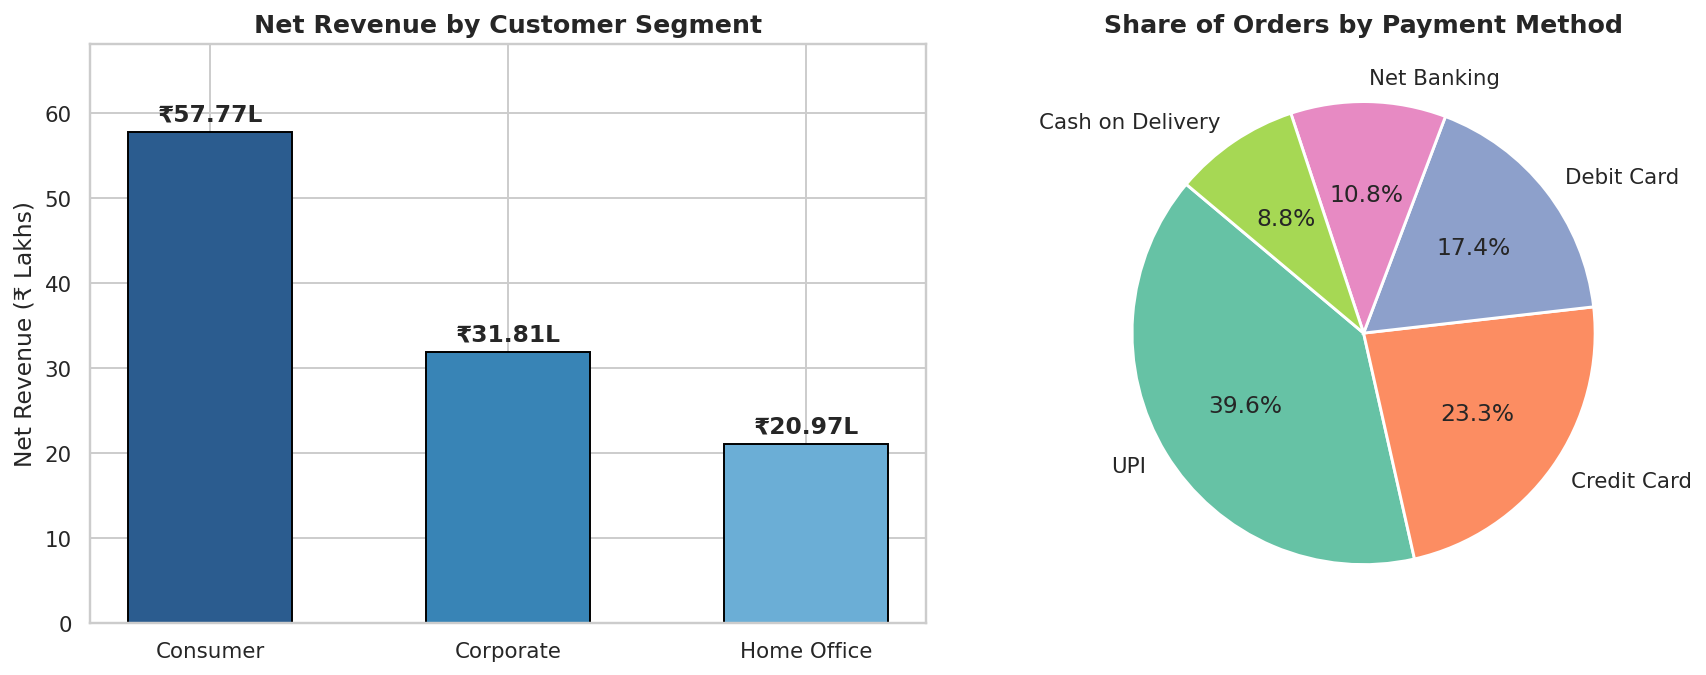

In [22]:
# Visualization 6.5: Customer Segment Revenue & Payment Method Share
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left subplot: Customer Segment Revenue
seg_bars = axes[0].bar(
    segment_summary["Customer_Segment"],
    segment_summary["Net_Revenue"] / 1e5,
    color=["#2b5c8f", "#3884b6", "#6baed6"],
    edgecolor="black",
    width=0.55
)
for bar in seg_bars:
    h = bar.get_height()
    axes[0].annotate(f"₹{h:.2f}L", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 6), textcoords="offset points", ha="center", fontweight="bold")
axes[0].set_title("Net Revenue by Customer Segment", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Net Revenue (₹ Lakhs)")
axes[0].set_ylim(0, (segment_summary["Net_Revenue"].max() / 1e5) * 1.18)

# Right subplot: Payment Method Order Distribution
axes[1].pie(
    payment_summary["Orders"],
    labels=payment_summary["Payment_Method"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2", len(payment_summary)),
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)
axes[1].set_title("Share of Orders by Payment Method", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

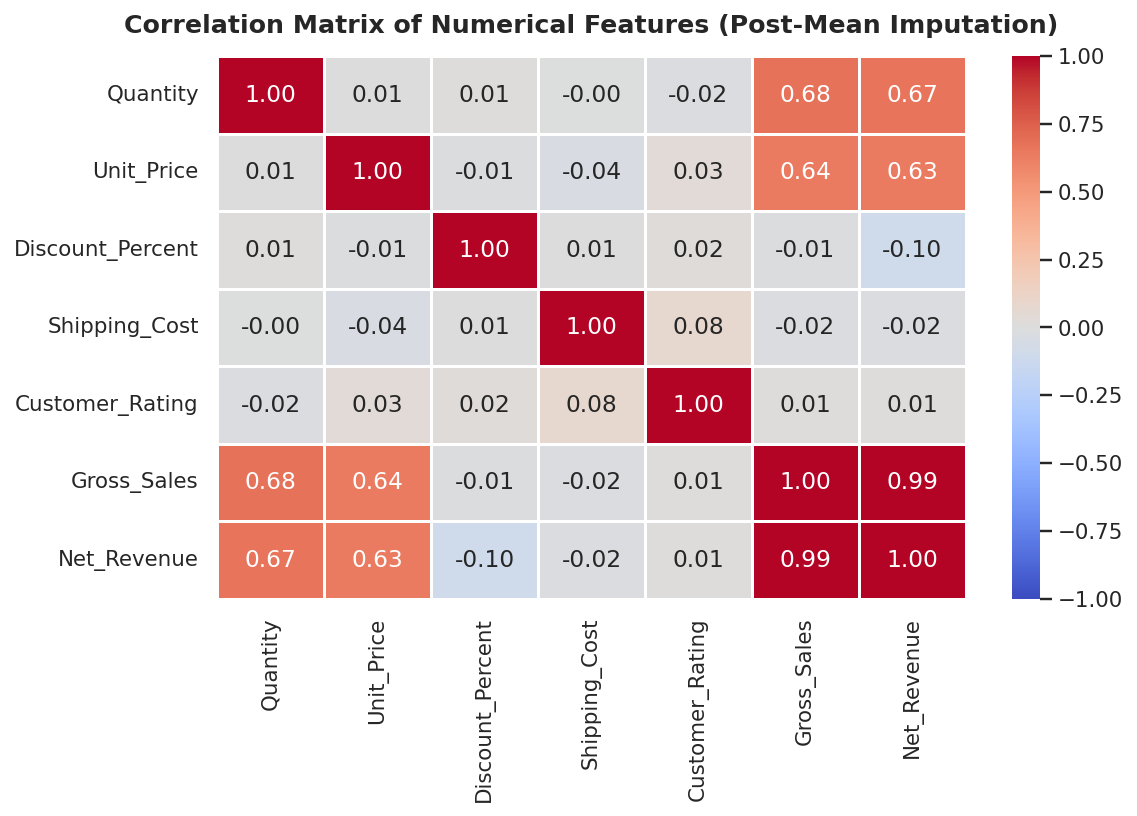

In [23]:
# Visualization 6.6: Correlation Heatmap of Numerical Features
num_features = ["Quantity", "Unit_Price", "Discount_Percent", "Shipping_Cost", "Customer_Rating", "Gross_Sales", "Net_Revenue"]
corr_matrix = df[num_features].corr()

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    ax=ax
)
ax.set_title("Correlation Matrix of Numerical Features (Post-Mean Imputation)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 7. Summary of Findings & Conclusions
1. **Null Value Handling via Mean Imputation**: All **600 missing entries** across `Quantity` (80), `Unit_Price` (120), `Discount_Percent` (140), `Shipping_Cost` (100), and `Customer_Rating` (160) were cleanly imputed using their respective column means, preserving all 2,500 transaction records without data loss.
2. **Seasonal Sales Surge**: Monthly revenue exhibits strong Q4 seasonality, peaking in **October and November 2025** due to festive demand.
3. **Top Performing Regions**: The **South** and **West** regions lead total revenue generation, together accounting for over **54%** of total net revenue.
4. **Dominant Product Categories**: **Electronics** and **Home & Kitchen** generate the highest revenue share due to higher average unit prices, while **Apparel** and **Electronics** drive the largest order volumes.
5. **Customer & Payment Trends**: The **Consumer** segment represents over half of total revenue, and digital payment modes (**UPI**, **Credit Card**, and **Debit Card**) account for more than **80%** of all transactions.